# QSO power spectra with blue/red/all repeat-error models

Compare **AbacusHF-v2, cutsky, base_dv, mock 0, GCcomb, 0.8 < z < 2.1** under
`repeat_blue`, `repeat_red`, and `repeat_all`. All three cases use the same underlying mock; the mock is
**not split by galaxy color**. The color selects the repeat-derived velocity-error distribution
applied to all mock objects before the final redshift cut.

The HCDF inputs use the direct extinction-corrected **r−W1** split from
`repeat_obs/notebooks/repeats_color_splits.ipynb`: either repeat redshift inside the bin,
threshold interpolated at the pair-mean redshift, constant endpoints, no clustering-label
membership requirement. Raw pair Δv values are used without a √2/2 conversion or deconvolution,
following the existing `repeat` convention. Sampling is symmetric in sign, with seed 1234;
catastrophic tails are retained. Catalog perturbations are Δz = Δv (1 + z) / c.

The `repeat_all` model uses all finite repeat pairs in the same bin, without a color cut.
For this QSO sample, blue and red partition all pairs exactly.

The input HCDF contains the full histogram and any exact-zero mass. Empty histogram bins
receive no sampling probability. Each model has its own output filename. GCcomb is the
pipeline's combination of separately measured NGC and SGC spectra. An existing no-added-error
measurement of the same mock is required as the clean reference.


In [1]:
import os
import sys
from pathlib import Path
import json
import hashlib

os.environ['MPICH_GPU_SUPPORT_ENABLED'] = '0'
os.environ['JAX_PLATFORMS'] = 'cpu'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lsstypes as types
from IPython.display import display

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'main/cat_tools.py').is_file())
sys.path.insert(0, str(REPO_ROOT / 'main'))
from cat_tools import get_measurement_fn, get_cov_fn
from clustering.clustering_covariance import get_saved_error_bars
from dv_tools import REPEAT_DIR

MOCK_ID = 0
REGION = 'GCcomb'
ZRANGE = (0.8, 2.1)
REBIN = 10                       # Original dk=0.001 -> approximately dk=0.01 h/Mpc.
KRANGE = (0.01, 0.30)
ELLS = (0, 2, 4)
MODELS = ('repeat_blue', 'repeat_red', 'repeat_all')
COLORS = {'repeat_blue': '#2a78d6', 'repeat_red': '#e34948', 'repeat_all': '#e69f00', 'None': '0.35'}
LABELS = {'repeat_blue': '+dv_repeats_blue', 'repeat_red': '+dv_repeats_red',
          'repeat_all': '+dv_repeats_all', 'None': 'clean'}
OUTPUT_DIR = REPO_ROOT / 'main/clustering/results/color_splits'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})

def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


## Repeat-error inputs

These are the HCDF files actually read by the catalog sampler. Their metadata records
input hashes, selection rules, and pair counts. The plots show the nonzero |Δv| distribution.


,model,N_pairs,N_catastrophic,N_zero
0,repeat_blue,127315,678,0
1,repeat_red,127796,2069,0
2,repeat_all,255111,2747,0


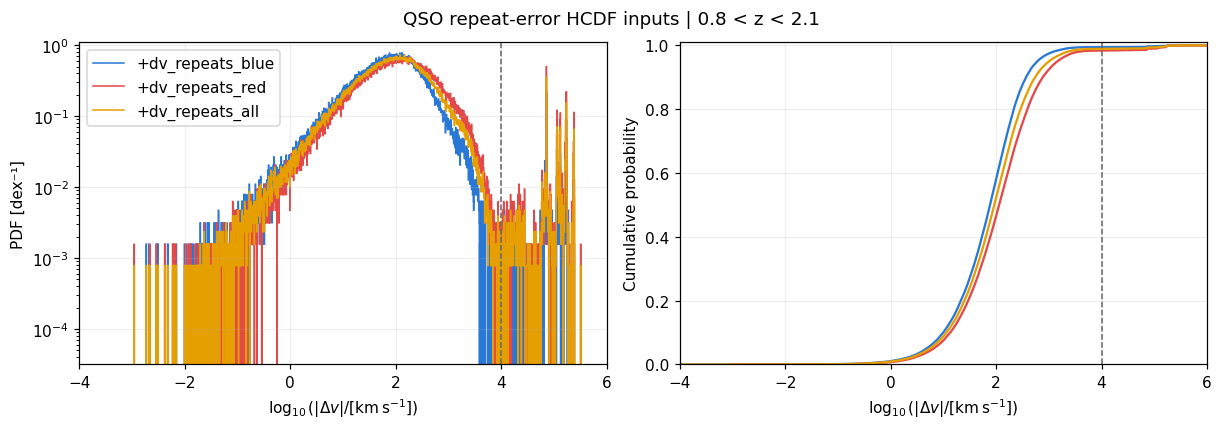

In [2]:
hcdfs, input_rows = {}, []
for mode in MODELS:
    color = mode.removeprefix('repeat_')
    path = REPEAT_DIR / 'DA2/loa-v1/repeat_mode' / f'HCDF_repeat_QSO_z0.8-2.1_log_abs_{color}.npz'
    with np.load(path, allow_pickle=False) as data:
        hcdfs[mode] = {key: data[key].copy() for key in ['edges', 'pdf', 'cdf', 'grid', 'counts']}
        metadata = json.loads(str(data['metadata_json']))
        assert int(data['counts'].sum()) + metadata['n_zero'] == metadata['n_selected']
        np.testing.assert_allclose(data['cdf'][-1], 1.)
    input_rows.append(dict(model=mode, N_pairs=metadata['n_selected'],
                           N_catastrophic=metadata['n_catastrophic'],
                           N_zero=metadata['n_zero'], N_all=metadata['n_all'], N_eligible=metadata['n_eligible'],
                           repeat_sha256=metadata['repeat_sha256'], threshold_sha256=metadata['threshold_sha256'],
                           path=str(path), sha256=sha256(path)))
inputs = pd.DataFrame(input_rows)
display(inputs[['model', 'N_pairs', 'N_catastrophic', 'N_zero']])
assert inputs.N_all.nunique() == inputs.N_eligible.nunique() == 1
assert inputs.repeat_sha256.nunique() == inputs.threshold_sha256.nunique() == 1
by_model = inputs.set_index('model')
assert by_model.loc[['repeat_blue', 'repeat_red'], 'N_pairs'].sum() == by_model.loc['repeat_all', 'N_pairs'] == inputs.N_all.iloc[0]
assert by_model.loc[['repeat_blue', 'repeat_red'], 'N_catastrophic'].sum() == by_model.loc['repeat_all', 'N_catastrophic']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
for mode, data in hcdfs.items():
    axes[0].stairs(data['pdf'], data['edges'], baseline=None, color=COLORS[mode], label=LABELS[mode])
    axes[1].plot(data['edges'][1:], data['cdf'], color=COLORS[mode], label=LABELS[mode])
for ax in axes:
    ax.set_xlim(-4, 6)
    ax.set_xlabel(r'$\log_{10}(|\Delta v|/[\mathrm{km\,s^{-1}}])$')
    ax.axvline(4, color='.4', ls='--', lw=1)
axes[0].set(yscale='log', ylim=(10**-4.5, None), ylabel='PDF [dex⁻¹]')
axes[1].set(ylim=(0, 1.01), ylabel='Cumulative probability')
axes[0].legend()
fig.suptitle('QSO repeat-error HCDF inputs | 0.8 < z < 2.1')
for ext in ['png', 'pdf']:
    fig.savefig(OUTPUT_DIR / f'qso_color_hcdf.{ext}', dpi=160)
plt.show()
plt.close(fig)


## Mock-0 power-spectrum multipoles

The lower panels show $(P_\ell^{+\Delta v}-P_\ell^{\rm clean})/\sigma_\ell^{\rm Holi}$
for blue, red, and all repeat errors, using `get_saved_error_bars` as in `plot_clustering.ipynb`.
The errors come from the saved clean holi-v3 altmtl QSO covariance (ALL region), matched
to the plotted bins and multipoles. They describe one realization, with no division by
$\sqrt{N_{\rm mocks}}$. The gray bands mark ±1σ around clean in the upper panels and around zero in the residual panels.

Only bins covered by the saved covariance have residuals; the upper panels keep the
requested k range. These curves express shifts relative to the Holi single-realization
scatter, not a significance computed from the covariance of paired mock differences.


clean: mesh2_spectrum_poles_QSO_z0.8-2.1_GCcomb_hf_v2.0_base_dv.h5
+dv_repeats_blue: mesh2_spectrum_poles_QSO_z0.8-2.1_GCcomb_hf_v2.0_base_dv+dv_repeat_blue.h5
+dv_repeats_red: mesh2_spectrum_poles_QSO_z0.8-2.1_GCcomb_hf_v2.0_base_dv+dv_repeat_red.h5
+dv_repeats_all: mesh2_spectrum_poles_QSO_z0.8-2.1_GCcomb_hf_v2.0_base_dv+dv_repeat_all.h5
Holi errors: 846 mocks; single-realization scatter; covariance coverage 0.02 < k < 0.35; covariance_mesh2_spectrum_poles_QSO_z0.8-2.1_holi_v3.h5


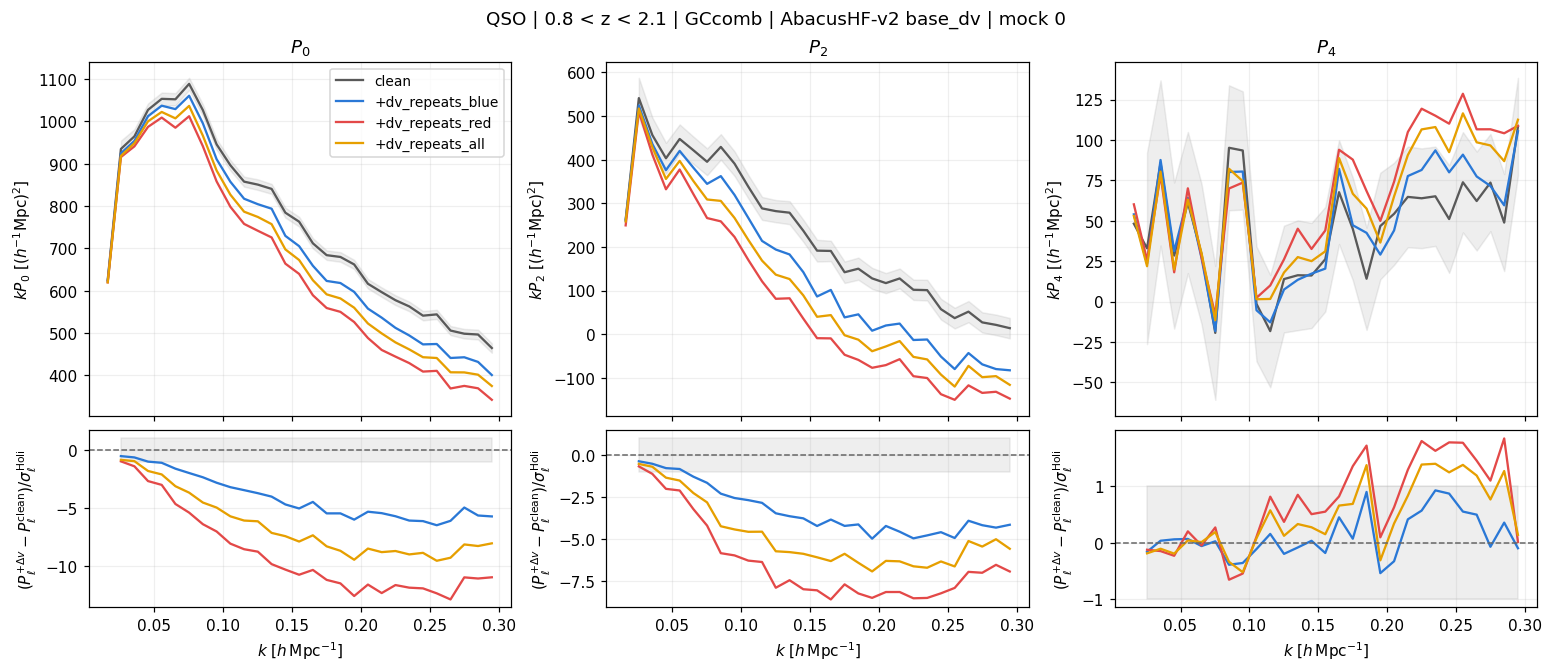

4002

In [3]:
catalog = dict(version='AbacusHF-v2', domain='cutsky', tracer='QSO', hod='base_dv',
               zsnap=1.4, zrange=ZRANGE, mock_id=MOCK_ID, region=REGION, z_evol=False)
def spectrum_path(mode):
    return Path(get_measurement_fn(**catalog, use_dv=mode, mkdir=False).format('mesh2_spectrum_poles'))
paths = {mode: spectrum_path(mode) for mode in MODELS}
for path in paths.values():
    if not path.is_file():
        raise FileNotFoundError(f'Missing spectrum: {path}. Run main/clustering/run_color_splits.sh first.')
clean = spectrum_path(False)
if not clean.is_file():
    raise FileNotFoundError(f'Missing clean reference spectrum: {clean}')
paths = {'None': clean, **paths}
power, kcoords, input_spectra = {}, {}, []
reference = None
for mode, path in paths.items():
    measurement = types.read(path).select(k=slice(0, None, REBIN)).select(k=KRANGE).get(ells=list(ELLS))
    if reference is None:
        reference = measurement
    power[mode] = {}
    for ell in ELLS:
        pole = measurement.get(ells=ell)
        np.testing.assert_allclose(pole.edges('k'), reference.get(ells=ell).edges('k'), rtol=1e-6, atol=1e-10)
        values = np.asarray(pole.value()).real
        k = np.asarray(pole.coords('k'))
        assert values.shape == k.shape and len(k) > 0 and np.isfinite(values).all()
        power[mode][ell] = values
        kcoords.setdefault(ell, k)
    input_spectra.append(dict(model=mode, file=str(path), sha256=sha256(path)))
    print(f'{LABELS[mode]}: {path.name}')

# Use the same clean Holi covariance configuration as plot_clustering.ipynb.
cov_args = dict(version='holi-v3', domain='altmtl', tracer='QSO', zsnap=1.4,
                zrange=ZRANGE, region='ALL', use_dv=False, z_evol=False, use_jax=True)
cov_path = Path(get_cov_fn(**cov_args).format('mesh2_spectrum_poles'))
saved_cov = types.read(cov_path)
cov_low = max(np.asarray(saved_cov.observable.get(ells=ell).edges('k'))[:, 0].min() for ell in ELLS)
cov_high = min(np.asarray(saved_cov.observable.get(ells=ell).edges('k'))[:, 1].max() for ell in ELLS)
residual_data = reference.select(k=(max(KRANGE[0], cov_low), min(KRANGE[1], cov_high)))
error_bars = get_saved_error_bars(cov_args, 'mesh2', residual_data, ells=ELLS, bin_type='test')
sigma_holi, residual_masks = {}, {}
for j, ell in enumerate(ELLS):
    edges = np.asarray(reference.get(ells=ell).edges('k'))
    mask = (edges[:, 0] >= cov_low - 1e-8) & (edges[:, 1] <= cov_high + 1e-8)
    np.testing.assert_allclose(edges[mask], residual_data.get(ells=ell).edges('k'), rtol=1e-6, atol=1e-10)
    assert error_bars[j].shape == kcoords[ell][mask].shape
    sigma_holi[ell] = error_bars[j]
    residual_masks[ell] = mask
print(f'Holi errors: {saved_cov.attrs["nobs"]} mocks; single-realization scatter; '
      f'covariance coverage {cov_low:g} < k < {cov_high:g}; {cov_path.name}')

fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex='col',
                         gridspec_kw={'height_ratios': [2, 1]}, layout='constrained')
for j, ell in enumerate(ELLS):
    k = kcoords[ell]
    for mode in paths:
        axes[0, j].plot(k, k * power[mode][ell], color=COLORS[mode], label=LABELS[mode])
    mask = residual_masks[ell]
    axes[0, j].fill_between(k[mask],
                            k[mask] * (power['None'][ell][mask] - sigma_holi[ell]),
                            k[mask] * (power['None'][ell][mask] + sigma_holi[ell]),
                            color=COLORS['None'], alpha=.10, zorder=0)
    axes[1, j].fill_between(k[mask], -1, 1, color=COLORS['None'], alpha=.10, zorder=0)
    for mode in MODELS:
        residual = (power[mode][ell][mask] - power['None'][ell][mask]) / sigma_holi[ell]
        assert np.isfinite(residual).all()
        axes[1, j].plot(k[mask], residual, color=COLORS[mode], label=LABELS[mode])
    axes[1, j].axhline(0, color='.4', ls='--', lw=1)
    axes[0, j].set_title(rf'$P_{{{ell}}}$')
    axes[0, j].set_ylabel(rf'$kP_{{{ell}}}$ [$(h^{{-1}}\mathrm{{Mpc}})^2$]')
    axes[1, j].set_ylabel(r'$(P_\ell^{+\Delta v}-P_\ell^{\rm clean})/\sigma_\ell^{\rm Holi}$')
    axes[1, j].set_xlabel(r'$k$ [$h\,\mathrm{Mpc}^{-1}$]')
axes[0, 0].legend(fontsize=9)
fig.suptitle(f'QSO | {ZRANGE[0]} < z < {ZRANGE[1]} | {REGION} | AbacusHF-v2 base_dv | mock {MOCK_ID}')
for ext in ['png', 'pdf']:
    fig.savefig(OUTPUT_DIR / f'qso_mock{MOCK_ID}_color_splits_pk.{ext}', dpi=160)
plt.show()
plt.close(fig)
arrays = {f'k_ell{ell}': kcoords[ell] for ell in ELLS}
arrays.update({f'{mode}_ell{ell}': values for mode, poles in power.items() for ell, values in poles.items()})
arrays.update({f'sigma_holi_ell{ell}': sigma_holi[ell] for ell in ELLS})
arrays.update({f'k_residual_ell{ell}': kcoords[ell][residual_masks[ell]] for ell in ELLS})
arrays.update({f'{mode}_residual_sigma_ell{ell}':
               (power[mode][ell][residual_masks[ell]] - power['None'][ell][residual_masks[ell]]) / sigma_holi[ell]
               for mode in MODELS for ell in ELLS})
np.savez(OUTPUT_DIR / f'qso_mock{MOCK_ID}_color_splits_pk.npz', **arrays)
provenance = dict(mock_id=MOCK_ID, region=REGION, zrange=ZRANGE, k_range=KRANGE,
                  rebin=REBIN, hcdf_inputs=inputs.to_dict(orient='records'), spectra=input_spectra,
                  residual_definition='(P_ell_model - P_ell_clean) / sigma_ell_holi',
                  covariance=dict(file=str(cov_path), sha256=sha256(cov_path),
                                  n_mocks=int(saved_cov.attrs['nobs']), catalog=cov_args,
                                  normalization='single realization; no SEM scaling',
                                  k_coverage=[float(cov_low), float(cov_high)]),
                  interpretation='same mock with three repeat-derived error distributions; not a mock color split')
(OUTPUT_DIR / f'qso_mock{MOCK_ID}_color_splits_provenance.json').write_text(json.dumps(provenance, indent=2) + '\n')


## Reproduce

Generate the three inputs (existing files are kept unless `--overwrite` is supplied):

```bash
python main/repeat_obs/model_repeats.py --tracers QSO --ztypes LSS \
    --bin_mode log_abs --cdf_mode histogram --colors blue red all
```

Then run `bash main/clustering/run_color_splits.sh`. It uses the requested four-GPU
allocation and computes `--regions NGC SGC GCcomb` because `GCcomb` itself only combines
existing NGC/SGC files. Afterward, the original `--region GCcomb` command can reuse those files.
The existing `repeat` model and original mock catalogs are unchanged.
